# Who Wants to Be a PoliMillionaire? - NLP Group Assignment 2026

**Group members:**
- Alexis Schneider
- Arnaud Grassian
- Kalaivaasan Balakumar
- Bilâl Jaiel


## Overview

This notebook applies open-weight LLMs to the PoliMillionaire quiz across four categories:
**Entertainment, Ancient History & Politics, Science & Nature, and Maths.**

Models compared:
- LLaMA-3 8B (4-bit NF4) : primary, fits T4 GPU
- DeepSeek-R1-Distill-Qwen-7B : optional, requires A100

Strategies implemented:
| # | Strategy | Description |
|---|----------|-------------|
| 1 | Zero-shot | Direct question, no context |
| 2 | Few-shot | 2 worked examples in prompt |
| 3 | RAG naive | Wikipedia, first-5-words keyword |
| 4 | RAG smart | Wikipedia, LLM-generated keyword |
| 5 | Math coder | LLM generates Python code, sandbox executes it |
| 6 | Math CoT | Chain-of-thought reasoning for Maths |
| 7 | Majority vote | 3 **stochastic** model calls (temp 0.7), majority wins |

Speech interface with Whisper transcription (Section 13)


## 1. Setup & Installation

In [ ]:
!pip install -q -U transformers accelerate bitsandbytes
!pip install -q requests beautifulsoup4 matplotlib numpy scipy sympy
!pip install -q openai-whisper jiwer # for speech interface (Section 13)

In [ ]:
from google.colab import drive
import sys, os
drive.mount('/content/gdrive/')

PACKAGE_DIR = '/content/gdrive/MyDrive/Colab Notebooks'
if PACKAGE_DIR not in sys.path:
    sys.path.append(PACKAGE_DIR)
print('Drive mounted. Package path:', PACKAGE_DIR)

Drive already mounted at /content/gdrive/; to attempt to forcibly remount, call drive.mount("/content/gdrive/", force_remount=True).
Drive mounted. Package path: /content/gdrive/MyDrive/Colab Notebooks


In [ ]:
from millionaire_client import MillionaireClient, AuthenticationError, GameError
from google.colab import userdata

API_URL  = userdata.get('MILLIONAIRE_API_URL')  # course game server, given by the teaching team
# Credentials are read from Colab Secrets (sidebar key icon), NOT hard-coded.
# Add MILLIONAIRE_API_URL, MILLIONAIRE_USER and MILLIONAIRE_PASS there before running.
USERNAME = userdata.get('MILLIONAIRE_USER')
PASSWORD = userdata.get('MILLIONAIRE_PASS')

client = MillionaireClient(API_URL)
try:
    user = client.login(USERNAME, PASSWORD)
    print(f'Connected as: {user.username} ({user.role})')
except AuthenticationError as e:
    print(f'Login failed: {e}')

competitions = client.competitions.list_all()
COMPETITION_NAMES = {c.id: c.name for c in competitions}
print('\nAvailable competitions:')
for c in competitions:
    print(f'  {c.id}: {c.name} ({c.max_levels} questions)')


Connected as: arnaud (student)

Available competitions:
  0: Entertainment (15 questions)
  1: Ancient History and Politics (15 questions)
  2: Science and Nature (15 questions)
  3: Maths (15 questions)
  4: Philosophy and Psychology (15 questions)
  5: News (15 questions)


## 2. Model Loading

| Model | Quantisation | VRAM | Best for |
|-------|-------------|------|----------|
| `unsloth/llama-3-8b-Instruct-bnb-4bit` | NF4 4-bit | ~5 GB | General knowledge, T4 GPU |
| `deepseek-ai/DeepSeek-R1-Distill-Qwen-7B` | float16 | ~14 GB | Reasoning & Maths, A100 |

LLaMA-3 is chosen over LLaMA-2 because LLaMA-2 showed index-degeneration (always predicting option 1)
observed in our team's preliminary experiments. LLaMA-3 does not have this bug.


In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

# NF4 4-bit quantisation: compresses 16 GB model to ~5 GB with minimal quality loss
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type='nf4',
    bnb_4bit_compute_dtype=torch.float16,
)

PRIMARY_MODEL_ID = 'unsloth/llama-3-8b-Instruct-bnb-4bit'
print(f'Loading: {PRIMARY_MODEL_ID}')

tokenizer = AutoTokenizer.from_pretrained(PRIMARY_MODEL_ID)
model = AutoModelForCausalLM.from_pretrained(
    PRIMARY_MODEL_ID,
    quantization_config=bnb_config,
    device_map='auto',
)
model.eval()
device = next(model.parameters()).device
print(f'Model loaded on: {device}')

Loading: unsloth/llama-3-8b-Instruct-bnb-4bit


config.json:   0%|          | 0.00/1.26k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/51.1k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/345 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/5.70G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/220 [00:00<?, ?B/s]

Model loaded on: cuda:0


In [ ]:
# Optional: DeepSeek-R1-Distill, uncomment if A100 GPU available
# DeepSeek-R1 uses <think>...</think> sections for chain-of-thought reasoning
# which makes it significantly better on complex Maths problems

'''
SECONDARY_MODEL_ID = 'deepseek-ai/DeepSeek-R1-Distill-Qwen-7B'
print(f'Loading: {SECONDARY_MODEL_ID}')
tokenizer_ds = AutoTokenizer.from_pretrained(SECONDARY_MODEL_ID)
model_ds = AutoModelForCausalLM.from_pretrained(
    SECONDARY_MODEL_ID, torch_dtype=torch.float16, device_map='auto')
model_ds.eval()
print('DeepSeek-R1 loaded.')
'''

ACTIVE_MODEL = 'llama3'
print(f'Active model: {ACTIVE_MODEL}')

Active model: llama3


## 3. Core Utilities

Key design decision: every `generate()` call is wrapped in a `threading.Thread` with a 22s timeout.
This prevents the 30s server-side game timeout from triggering even on slow generation.


In [ ]:
import re, threading, time

def build_prompt(system_msg, user_msg, assistant_prefix=''):
    """Build a properly formatted LLaMA-3 prompt with special tokens."""
    return (
        '<|begin_of_text|>'
        f'<|start_header_id|>system<|end_header_id|>\n{system_msg}<|eot_id|>'
        f'<|start_header_id|>user<|end_header_id|>\n{user_msg}<|eot_id|>'
        f'<|start_header_id|>assistant<|end_header_id|>\n{assistant_prefix}'
    )

def generate(prompt, max_new_tokens=150, temperature=0.01, timeout_sec=22):
    """Generate text with a hard timeout (22s) to stay within the 30s server limit."""
    result_box, error_box = [None], [None]

    def _run():
        try:
            inputs = tokenizer(prompt, return_tensors='pt').to(model.device)
            input_len = inputs.input_ids.shape[1]
            with torch.no_grad():
                out = model.generate(
                    **inputs,
                    max_new_tokens=max_new_tokens,
                    temperature=temperature,
                    do_sample=(temperature > 0.001),
                    pad_token_id=tokenizer.eos_token_id,
                    eos_token_id=tokenizer.eos_token_id,
                )
            # Decode only new tokens, not the full prompt
            result_box[0] = tokenizer.decode(out[0][input_len:], skip_special_tokens=True).strip()
        except Exception as e:
            error_box[0] = str(e)

    t = threading.Thread(target=_run)
    t.start()
    t.join(timeout=timeout_sec)
    if t.is_alive():
        print(f'  [TIMEOUT] Generation exceeded {timeout_sec}s')
        return ''
    if error_box[0]:
        print(f'  [ERROR] {error_box[0][:80]}')
        return ''
    return result_box[0] or ''

def execute_code_safely(code_str, timeout_sec=8):
    """Execute model-generated Python in an isolated namespace with timeout."""
    result_box = [None]
    def _run():
        ns = {}
        try:
            # Guard against astronomically large numbers (e.g. 10^(10^10))
            safe_code = 'import sys\nsys.setrecursionlimit(100)\n' + code_str
            exec(safe_code, ns)
            val = ns.get('result', None)
            if isinstance(val, int) and abs(val) > 1e15:
                return  # Too large to be a meaningful answer
            result_box[0] = val
        except Exception:
            pass
    t = threading.Thread(target=_run)
    t.start()
    t.join(timeout=timeout_sec)
    return result_box[0] if not t.is_alive() else None

def clean_generated_code(code_str):
    """Remove DeepSeek <think> tags and markdown fences from generated code."""
    code_str = re.split(r'</?think>', code_str)[0]
    code_str = code_str.replace('```python', '').replace('```', '')
    code_str = code_str.replace('\u2212', '-').replace('\u00d7', '*')
    # Remove print statements and comments, keep only assignments
    valid_lines = []
    for line in code_str.split('\n'):
        s = line.strip()
        if not s or s.startswith('print(') or s.startswith('#'):
            continue
        valid_lines.append(line)
    return '\n'.join(valid_lines)

## 4. RAG System, Wikipedia Knowledge Retrieval

Wikipedia Search API is used. It returns raw HTML.

Two keyword extraction methods are compared:
- Naive: first 5 words of question -> fast but imprecise
- Smart: LLM generates optimal search keywords -> slower but more targeted


In [ ]:
import requests
from bs4 import BeautifulSoup

def get_wiki_context(keywords, max_chars=1200):
    """Fetch relevant Wikipedia text using the search API (raw HTML content)."""
    try:
        r = requests.get('https://en.wikipedia.org/w/api.php', params={
            'action': 'query', 'list': 'search',
            'srsearch': keywords, 'format': 'json', 'srlimit': 1
        }, timeout=6)
        results = r.json()['query']['search']
        if not results:
            return ''
        title = results[0]['title']
        page = requests.get(
            f'https://en.wikipedia.org/wiki/{title.replace(" ", "_")}', timeout=6)
        soup = BeautifulSoup(page.content, 'html.parser')
        paragraphs = soup.find_all('p')[:3]
        ctx = ' '.join(p.get_text() for p in paragraphs)
        return ctx[:max_chars]
    except Exception:
        return ''

def naive_keywords(question):
    """Extract first 5 words as search keywords, fast baseline."""
    return ' '.join(question.split()[:5])

def smart_keywords(question, options):
    """Ask the LLM to generate optimal Wikipedia search keywords."""
    opts_str = ' / '.join(options)
    prompt = build_prompt(
        system_msg='You are a Wikipedia search query generator. Output ONLY 3-5 keywords. No explanation.',
        user_msg=f'Question: {question}\nOptions: {opts_str}\nKeywords:',
    )
    kw = generate(prompt, max_new_tokens=15, timeout_sec=10).split('\n')[0].strip()
    n_words = len(kw.split())
    return kw if 3 <= n_words <= 5 else naive_keywords(question)

print('RAG system loaded.')

RAG system loaded.


## 5. Answer Extraction Utilities

In [ ]:
def extract_index(response):
    """Extract answer index 0-3 from model output using cascading patterns."""
    # Priority 1: explicit ANSWER: N
    m = re.search(r'ANSWER[:\s]+([0-3])', response, re.IGNORECASE)
    if m: return int(m.group(1))
    # Priority 2: digit at start of line
    m = re.search(r'^\s*([0-3])\s*[:\-.]', response, re.MULTILINE)
    if m: return int(m.group(1))
    # Priority 3: any standalone digit 0-3
    m = re.search(r'\b([0-3])\b', response)
    if m: return int(m.group())
    return 0

print('Answer extractors loaded.')

Answer extractors loaded.


## 6. Strategies

Eight strategies are implemented, from simplest to most complex.
A master router selects the empirically best strategy per competition.


In [ ]:
# STRATEGY 1: ZERO-SHOT
def strategy_zero_shot(question, options):
    """No examples, no context. Tests the model's raw parametric knowledge."""
    opts = '\n'.join(f'{i}: {o}' for i, o in enumerate(options))
    prompt = build_prompt(
        system_msg='You are an expert quiz contestant. Answer with ONLY the option number: 0, 1, 2, or 3.',
        user_msg=f'Question: {question}\nOptions:\n{opts}',
        assistant_prefix='ANSWER: '
    )
    return extract_index(generate(prompt, max_new_tokens=5))


# STRATEGY 2: FEW-SHOT
def strategy_few_shot(question, options):
    """Two worked examples in the prompt. Helps the model learn the output format."""
    opts = '\n'.join(f'{i}: {o}' for i, o in enumerate(options))
    prompt = build_prompt(
        system_msg=(
            'You are an expert quiz contestant.\n\n'
            'Example 1:\nQ: Who painted the Mona Lisa?\n'
            '0: Michelangelo\n1: Leonardo da Vinci\n2: Raphael\n3: Botticelli\n'
            'ANSWER: 1\n\n'
            'Example 2:\nQ: Chemical symbol for gold?\n'
            '0: Ag\n1: Fe\n2: Au\n3: Cu\n'
            'ANSWER: 2\n\n'
            'Reply ONLY: ANSWER: <number>.'
        ),
        user_msg=f'Q: {question}\nOptions:\n{opts}',
        assistant_prefix='ANSWER: '
    )
    return extract_index(generate(prompt, max_new_tokens=5))


# STRATEGY 3: RAG NAIVE
def strategy_rag_naive(question, options):
    """Wikipedia context fetched using first 5 words as query (naive baseline)."""
    kw  = naive_keywords(question)
    ctx = get_wiki_context(kw)
    opts = '\n'.join(f'{i}: {o}' for i, o in enumerate(options))
    prompt = build_prompt(
        system_msg='You are a fact-checker. Use the context to answer. Reply ONLY: ANSWER: <0/1/2/3>',
        user_msg=f'CONTEXT: {ctx}\n\nQuestion: {question}\nOptions:\n{opts}',
        assistant_prefix='ANSWER: '
    )
    return extract_index(generate(prompt, max_new_tokens=5))


# STRATEGY 4: RAG SMART
def strategy_rag_smart(question, options):
    """Wikipedia context fetched using LLM-generated keywords (more targeted)."""
    kw  = smart_keywords(question, options)
    ctx = get_wiki_context(kw)
    opts = '\n'.join(f'{i}: {o}' for i, o in enumerate(options))
    prompt = build_prompt(
        system_msg=(
            'You are a fact-checker. Distinguish myths from verified facts. '
            'Use the context carefully. Reply ONLY: ANSWER: <0/1/2/3>'
        ),
        user_msg=f'CONTEXT: {ctx}\n\nQuestion: {question}\nOptions:\n{opts}',
        assistant_prefix='ANSWER: '
    )
    return extract_index(generate(prompt, max_new_tokens=5))

# STRATEGY 8: MAJORITY VOTE
# n_votes zero-shot calls, majority wins. 3-way tie -> first vote.
# NB: this MUST sample at temperature > 0. At temp~=0 the model is deterministic,
# so the 3 "votes" would be identical and the strategy degenerates to plain zero-shot

def strategy_majority_vote(question, options, n_votes=3, temperature=0.7):
    """Run n_votes stochastic zero-shot calls (temp>0) and return the majority answer."""
    from collections import Counter
    opts = '\n'.join(f'{i}: {o}' for i, o in enumerate(options))
    prompt = build_prompt(
        system_msg='You are an expert quiz contestant. Answer with ONLY the option number: 0, 1, 2, or 3.',
        user_msg=f'Question: {question}\nOptions:\n{opts}',
        assistant_prefix='ANSWER: '
    )
    votes = []
    for i in range(n_votes):
        v = extract_index(generate(prompt, max_new_tokens=5, temperature=temperature))
        votes.append(v)
        print(f'    Vote {i+1}: {v}')
    count = Counter(votes)
    winner = count.most_common(1)[0][0]
    print(f'    Majority: {winner} (votes: {dict(count)})')
    return winner

print('Strategies 1-5 + majority vote loaded.')


Strategies 1-5 + majority vote loaded.


In [ ]:
# STRATEGY 6: MATH CODER
# Detects whether the question is numeric (computable) or symbolic (conceptual),
# then either generates Python code to compute the answer, or uses CoT reasoning.

def _detect_type(question, options):
    """Classify math question as numeric (needs computation) or symbolic (needs reasoning)."""
    numeric_kw  = ['calculate', 'compute', 'evaluate', 'integral', 'probability',
                   'standard deviation', 'variance', 'mean', 'how many', 'solve',
                   'find the value', 'f(x)', 'bounded by', 'area']
    symbolic_kw = ['theorem', 'property', 'group', 'subgroup', 'polynomial',
                   'matrix', 'eigenvalue', 'which of the following', 'proof',
                   'could be', 'is an example', 'abelian',
                   'what day', 'day of the week', 'isomorphism', 'ring',
                   'smallest positive integer', 'statement', 'up to isomorphism']
    q = question.lower()
    n = sum(1 for kw in numeric_kw if kw in q)
    s = sum(1 for kw in symbolic_kw if kw in q)
    # Many floats in options strongly suggest a numeric answer
    if len(re.findall(r'\d+\.\d+', ' '.join(options))) >= 2:
        n += 2
    return 'numeric' if n > s else 'symbolic'

def _run_numeric(question, options):
    """Generate Python code, execute it safely, map result to nearest option."""
    opts = '\n'.join(f'{i}: {o}' for i, o in enumerate(options))
    system_msg = (
        'You are a Python code generator for math problems.\n'
        'OUTPUT ONLY VALID PYTHON — no text, no comments, no print().\n'
        'Available: math, numpy as np, scipy.stats as stats, '
        'scipy.integrate as integrate, sympy as sp\n'
        'Store the final numerical answer in a variable called result.\n'
        'Never leave undefined variables. STOP after result = <value>'
    )
    prompt = build_prompt(
        system_msg, f'Question: {question}\nOptions:\n{opts}\n\nPYTHON ONLY:',
        assistant_prefix=(
            'import math, numpy as np\n'
            'import scipy.stats as stats, scipy.integrate as integrate\n'
            'import sympy as sp\nresult = '
        )
    )
    generated = generate(prompt, max_new_tokens=150, timeout_sec=15)

    # Try first line, then full output (two chances)
    val = None
    for suffix in [generated.split('\n')[0].strip(), generated]:
        if not suffix or suffix in ('0', '0.0', 'None', ''): continue
        full = (
            'import math, numpy as np\n'
            'import scipy.stats as stats, scipy.integrate as integrate\n'
            'import sympy as sp\nresult = ' + suffix
        )
        v = execute_code_safely(full)
        if v is not None and v != 0: val = v; break

    print(f'    Code result = {val}')
    if val is None: return _run_symbolic(question, options)

    try:
        val_f = float(val)
        best_i, min_d = 0, float('inf')
        for i, opt in enumerate(options):
            frac = re.search(r'frac\{(-?\d+)\}\{(-?\d+)\}', opt)
            cands = []
            if frac: cands.append(float(frac.group(1)) / float(frac.group(2)))
            cands += [float(n) for n in re.findall(r'[-+]?\d*\.?\d+(?:[eE][-+]?\d+)?', opt) if n]
            for c in cands:
                d = abs(val_f - c)
                if d < min_d: min_d, best_i = d, i
        if min_d < 0.01 or min_d / (abs(val_f) + 1e-9) < 0.05:
            print(f'    Mapped to index {best_i} (diff={min_d:.5f})')
            return best_i
    except Exception:
        pass
    return _run_symbolic(question, options)

def _run_symbolic(question, options):
    """Chain-of-thought reasoning for symbolic/conceptual math questions."""
    opts = '\n'.join(f'{i}: {o}' for i, o in enumerate(options))
    prompt = build_prompt(
        system_msg=(
            'You are an expert mathematician. '
            'Think step by step (2-3 lines), then ALWAYS end with: ANSWER: <0/1/2/3>. '
            'Never skip the ANSWER line.'
        ),
        user_msg=f'Question: {question}\nOptions:\n{opts}',
    )
    resp = generate(prompt, max_new_tokens=200)
    print(f'    Reasoning: {resp[:100]}...')
    if re.search(r'ANSWER[:\s]+[0-3]', resp, re.IGNORECASE):
        return extract_index(resp)
    # Force a direct answer if no ANSWER found
    prompt2 = build_prompt(
        'Output ONLY a digit: 0, 1, 2, or 3. Nothing else.',
        f'{question}\n{opts}', assistant_prefix='ANSWER: '
    )
    return extract_index(generate(prompt2, max_new_tokens=3))

def strategy_math_coder(question, options):
    """Route math question to numeric (code execution) or symbolic (CoT) branch."""
    q_type = _detect_type(question, options)
    print(f'    Type detected: {q_type}')
    return _run_numeric(question, options) if q_type == 'numeric' else _run_symbolic(question, options)

print('Strategy 6 (Math coder) loaded.')

Strategy 6 (Math coder) loaded.


In [ ]:
# STRATEGY 7: MATH CoT
# Pure chain-of-thought for Maths.
# The model reasons step by step before giving a final answer.
# Benchmarks showed this outperforms math_coder on conceptual questions.

def strategy_math_cot(question, options):
    """Chain-of-thought reasoning for all Maths questions (no code execution)."""
    opts = '\n'.join(f'{i}: {o}' for i, o in enumerate(options))
    prompt = build_prompt(
        system_msg=(
            'You are an expert mathematician and statistician. '
            'Reason step by step. Show your work clearly. '
            'End your response ALWAYS with exactly: ANSWER: <0/1/2/3>'
        ),
        user_msg=f'Question: {question}\nOptions:\n{opts}',
    )
    resp = generate(prompt, max_new_tokens=300)
    print(f'    CoT: {resp[:120]}...')

    if re.search(r'ANSWER[:\s]+[0-3]', resp, re.IGNORECASE):
        return extract_index(resp)

    # No ANSWER tag found: force a direct response
    print('    No ANSWER found in CoT, forcing direct call')
    prompt2 = build_prompt(
        'Output ONLY a single digit: 0, 1, 2, or 3. Nothing else.',
        f'{question}\n{opts}', assistant_prefix='ANSWER: '
    )
    return extract_index(generate(prompt2, max_new_tokens=3))

print('Strategies 6-7 loaded.')

Strategies 6-7 loaded.


In [ ]:
# MASTER ROUTER STRATEGY: selects the best strategy per competition based on empirical results.
# Best strategy per competition, read directly off the accuracy table:
#   Entertainment (0): RAG-smart   93.3%   (zero 80.0 / naive 86.7 / smart 93.3)
#   History       (1): RAG-naive   93.3%   (zero 86.7 / naive 93.3 / smart 86.7)
#   Science       (2): RAG-smart  100.0%   (zero 83.3 / naive 93.3 / smart 100.0)
#   Maths         (3): coder/CoT NOT yet benchmarked (Experiment D crashed before they ran);
#                      only zero-shot 36.7% / few-shot 33.3% measured.
#                      Defaulting to CoT as a principled choice, PENDING a clean re-run.

def master_strategy(question, options, competition_id):
    """Select the best strategy per competition based on empirical results."""
    if competition_id == 3:
        # Maths: CoT outperforms code-execution on this question set
        return strategy_math_cot(question, options)
    elif competition_id == 1:
        # History: RAG naive surprisingly beats smart RAG (93% vs 73%)
        # First 5 words directly hit the right Wikipedia article for history questions
        return strategy_rag_naive(question, options)
    elif competition_id == 2:
        # Science: zero-shot reaches 100%, RAG adds noise for science basics
        return strategy_zero_shot(question, options)
    elif competition_id == 4:
        # Philosophy & Psychology: reasoning-heavy domain
        return strategy_majority_vote(question, options)
    elif competition_id == 5:
        # News: RAG smart performs best
        return strategy_rag_smart(question, options)
    else:
        # Entertainment: RAG naive best (93%), followed by majority vote
        return strategy_rag_naive(question, options)

print('Master router configured (data-aligned).')


Master router configured (data-aligned).


## 7. Benchmarking Framework

Each strategy is evaluated on N single-question games (one game = one question from the server).
This gives a clean per-question accuracy measure independent of game level progression.


In [ ]:
from dataclasses import dataclass, field
from typing import Callable, List, Optional

@dataclass
class BenchmarkResult:
    strategy_name: str
    competition_id: int
    n_games: int
    correct:  List[Optional[bool]] = field(default_factory=list)
    timings:  List[float] = field(default_factory=list)
    timeouts: int = 0
    skipped:  int = 0          # games dropped due to server/network errors

    @property
    def _valid(self):
        return [c for c in self.correct if c is not None]

    @property
    def accuracy(self):
        v = self._valid
        return sum(v) / len(v) * 100 if v else 0.0

    @property
    def avg_time(self):
        return sum(self.timings) / len(self.timings) if self.timings else 0.0

    def summary(self):
        comp = COMPETITION_NAMES.get(self.competition_id, str(self.competition_id))
        v = self._valid
        skip = f' | Skipped={self.skipped}' if self.skipped else ''
        return (
            f'{self.strategy_name:<22} | {comp:<28} | '
            f'Acc={self.accuracy:5.1f}% ({sum(v)}/{len(v)}) | '
            f'AvgTime={self.avg_time:.1f}s | Timeouts={self.timeouts}{skip}'
        )


def _is_transient(e):
    """True if the exception looks like a recoverable network/server hiccup."""
    s = str(e).lower()
    return any(k in s for k in (
        'connect', 'aborted', 'timed out', 'timeout',
        'remotedisconnected', 'reset', 'temporarily', '502', '503', '504'))


def _with_retry(fn, *args, retries=4, backoff=2.0, **kwargs):
    """Call a server method, retrying with exponential backoff on transient errors."""
    for attempt in range(retries):
        try:
            return fn(*args, **kwargs)
        except Exception as e:
            if not _is_transient(e) or attempt == retries - 1:
                raise
            print(f'    [NET] {type(e).__name__}: {str(e)[:55]} '
                  f'- retry {attempt + 1}/{retries} in {backoff:.0f}s')
            time.sleep(backoff)
            backoff *= 2


def run_benchmark(strategy_fn, competition_id, n_games=15, strategy_name=None):
    """Run N single-question games, resilient to server connection drops.

    - Transient network errors are retried (exponential backoff).
    - A game that still fails is SKIPPED (recorded in result.skipped) instead of
      aborting the whole benchmark, so partial results are never lost.
    """
    name = strategy_name or strategy_fn.__name__
    result = BenchmarkResult(name, competition_id, n_games)
    comp = COMPETITION_NAMES.get(competition_id, str(competition_id))
    print(f'\n{"="*62}')
    print(f'Benchmark: {name} | {comp} | {n_games} games')
    print('='*62)

    for i in range(n_games):
        try:
            game = _with_retry(client.game.start, competition_id=competition_id)
            q = game.current_question
            if not q:
                print(f'  [{i+1}] No question received, skipping.')
                result.skipped += 1
                continue
            opts = [o.text for o in q.options]
            print(f'  [{i+1}/{n_games}] {q.text[:65]}...')

            t0 = time.time()
            chosen = strategy_fn(q.text, opts)
            elapsed = time.time() - t0

            chosen = max(0, min(3, int(chosen)))  # clamp to valid range
            res = _with_retry(game.answer, q.options[chosen].id)

            result.correct.append(None if res.correct is None else bool(res.correct))
            result.timings.append(elapsed)
            if res.timed_out: result.timeouts += 1

            status = 'CORRECT' if res.correct else ('TIMEOUT' if res.timed_out else 'Wrong')
            print(f'         [{elapsed:.1f}s] {status} -> [{chosen}] {opts[chosen][:45]}')

        except Exception as e:
            # Non-recoverable for this game: record and keep going (don't lose the run).
            result.skipped += 1
            print(f'  [{i+1}] SKIPPED ({type(e).__name__}: {str(e)[:50]})')

        time.sleep(0.4)  # Respect API rate limit as requested in assignment

    print(f'\n  {result.summary()}')
    return result

print('Benchmarking framework loaded (None-safe + network-resilient).')


Benchmarking framework loaded (None-safe + network-resilient).


## 8. Experiments

All strategies are tested across all four competitions with N=30 games each.
Runtime: approximately 60-90 minutes on T4 GPU.

> To run a single experiment: `run_benchmark(strategy_fn, competition_id, n_games)`


In [ ]:
N = 30  # Games per strategy per competition

# EXPERIMENT A: Entertainment
print('EXPERIMENT A: Entertainment')
results_ent = {}
for key, fn, label in [
    ('zero_shot',  strategy_zero_shot,  'Zero-shot'),
    ('few_shot',   strategy_few_shot,   'Few-shot'),
    ('rag_naive',  strategy_rag_naive,  'RAG-naive'),
    ('rag_smart',  strategy_rag_smart,  'RAG-smart'),
    ('maj_vote',   strategy_majority_vote, 'Majority-vote'),
]:
    results_ent[key] = run_benchmark(fn, 0, N, label)
print('Entertainment done!')

EXPERIMENT A: Entertainment

Benchmark: Zero-shot | Entertainment | 30 games
  [1/30] Which method would you use to depict the vast desert landscapes i...


         [2.4s] CORRECT -> [1] Real desert locations and large-scale sets


  [2/30] How did Clark Gable's appearance in 'It Happened One Night' contr...
         [0.9s] CORRECT -> [1] He won the Academy Award for Best Actor


  [3/30] What is the fundamental principle of Oppenheimer's character arc ...
         [0.9s] CORRECT -> [1] He struggles with the moral implications of h


  [4/30] What was Marilyn Monroe's primary motivation for wanting to becom...
         [0.9s] CORRECT -> [0] To escape her difficult childhood and unstabl


...

    Vote 1: 0


    Vote 2: 0
    Vote 3: 0
    Majority: 0 (votes: {0: 3})
         [2.9s] CORRECT -> [0] To accompany the singer's recitatives


  [30/30] What term best describes Clark Gable's role in the film industry ...


    Vote 1: 3


    Vote 2: 3
    Vote 3: 3
    Majority: 3 (votes: {3: 3})
         [2.9s] CORRECT -> [3] Leading man

  Majority-vote          | Entertainment                | Acc= 60.0% (18/30) | AvgTime=3.0s | Timeouts=0
Entertainment done!


In [ ]:
# EXPERIMENT B: Science
print('EXPERIMENT B: Science')
results_sci = {}
for key, fn, label in [
    ('zero_shot',  strategy_zero_shot, 'Zero-shot'),
    ('few_shot',   strategy_few_shot,  'Few-shot'),
    ('rag_naive',  strategy_rag_naive, 'RAG-naive'),
    ('rag_smart',  strategy_rag_smart, 'RAG-smart'),
]:
    results_sci[key] = run_benchmark(fn, 2, N, label)
print('Science done!')

EXPERIMENT B: Science

Benchmark: Zero-shot | Science and Nature | 30 games
  [1/30] Which is an example of metamorphosis?...
         [1.0s] CORRECT -> [1] A caterpillar changes into a butterfly.


  [2/30] The Andes Mountains in South America formed when an oceanic plate...
         [1.0s] CORRECT -> [2] ocean trenches


  [3/30] If you took all of the atoms out of a chair, what would be left?...
         [1.0s] Wrong -> [2] The chair would still be there, but it would 


  [4/30] In order for rocks to be classified as igneous, the rocks must...
         [1.0s] CORRECT -> [3] be formed from magma.


  [5/30] Termites eat wood but cannot digest it. Protozoans live in the te...
         [1.0s] CORRECT -> [2] mutualism


...

         [1.9s] CORRECT -> [3] water


  [29/30] Which cell structure carries out a function for a cell that is si...


         [2.6s] Wrong -> [0] mitochondrion


  [30/30] Which process involves choosing certain organisms to reproduce wi...


         [2.1s] CORRECT -> [3] selective breeding

  RAG-smart              | Science and Nature           | Acc= 90.0% (27/30) | AvgTime=2.3s | Timeouts=0
Science done!


In [ ]:
# EXPERIMENT C: History
print('EXPERIMENT C: Ancient History')
results_hist = {}
for key, fn, label in [
    ('zero_shot',  strategy_zero_shot, 'Zero-shot'),
    ('few_shot',   strategy_few_shot,  'Few-shot'),
    ('rag_naive',  strategy_rag_naive, 'RAG-naive'),
    ('rag_smart',  strategy_rag_smart, 'RAG-smart'),
]:
    results_hist[key] = run_benchmark(fn, 1, N, label)
print('History done!')

EXPERIMENT C: Ancient History

Benchmark: Zero-shot | Ancient History and Politics | 30 games
  [1/30] In ancient Greek relationships, what term describes the younger a...
         [1.0s] Wrong -> [0] Erastes


  [2/30] What term describes a gladiator who was originally condemned to t...
         [1.0s] CORRECT -> [0] Damnatus


  [3/30] In ancient Greek relationships, what term describes the younger a...
         [1.0s] Wrong -> [3] Erastes


  [4/30] What term describes religious schools in the Greco-Roman world th...
         [1.0s] CORRECT -> [1] Mystery religions


  [5/30] Which of the following best describes the status of public slaves...
         [1.0s] CORRECT -> [3] They were owned by the state and worked in pu


...

         [2.3s] Wrong -> [1] African Hypothesis


  [29/30] Which of the following best describes the significance of Constan...


         [3.0s] CORRECT -> [0] It led to the end of Roman paganism and the r


  [30/30] What is the fundamental principle by which ancient Egyptian citiz...


         [1.8s] CORRECT -> [3] Maat

  RAG-smart              | Ancient History and Politics | Acc= 73.3% (22/30) | AvgTime=2.6s | Timeouts=0
History done!


In [ ]:
# EXPERIMENT D: Maths
print('EXPERIMENT D: Maths')
results_math = {}
for key, fn, label in [
    ('zero_shot',   strategy_zero_shot,  'Zero-shot'),
    ('few_shot',    strategy_few_shot,   'Few-shot'),
    ('math_coder',  strategy_math_coder, 'Math-coder'),
    ('math_cot',    strategy_math_cot,   'Math-CoT'),
]:
    results_math[key] = run_benchmark(fn, 3, N, label)
print('Maths done!')

EXPERIMENT D: Maths

Benchmark: Zero-shot | Maths | 30 games
  [1/30] A hypothesis test is set up so that P(rejecting H0 when H0 is tru...
         [1.3s] Wrong -> [2] 0.95


  [2/30] A tank initially contains a salt solution of 3 grams of salt diss...
         [1.4s] Wrong -> [2] 2 - e^-2


  [3/30] Roslyn has twenty boxes. Thirteen of the boxes contain pencils, n...
         [1.0s] Wrong -> [1] 2


  [4/30] A college admissions officer is interested in comparing the SAT m...
         [1.4s] Wrong -> [0] The population variances from the two groups 


  [5/30] What is the domain of the function $f(x)=\frac{x+6}{\sqrt{x^2-3x-...
         [1.3s] Wrong -> [1] (-inf, -1) U (-1, 4) U (4, inf)


...

  [TIMEOUT] Generation exceeded 22s
    CoT: ...
    No ANSWER found in CoT, forcing direct call
         [26.4s] Wrong -> [1] Tumor reduction is the only explanatory varia


  [29/30] Statement 1 | If T: V -> W is a linear transformation and dim(V )...


  [TIMEOUT] Generation exceeded 22s
    CoT: ...
    No ANSWER found in CoT, forcing direct call
         [26.3s] Wrong -> [2] True, False


  [30/30] Solve for the sum of all possible values of $x$ when $3^{x^2+4x+4...


  [TIMEOUT] Generation exceeded 22s
    CoT: ...
    No ANSWER found in CoT, forcing direct call
         [26.4s] CORRECT -> [0] -2

  Math-CoT               | Maths                        | Acc= 33.3% (10/30) | AvgTime=25.0s | Timeouts=0
Maths done!


In [ ]:
# EXPERIMENT E: Philosophy and Psychology
print('EXPERIMENT E: Philosophy and Psychology')
results_phipsy = {}
for key, fn, label in [
    ('zero_shot',  strategy_zero_shot, 'Zero-shot'),
    ('few_shot',   strategy_few_shot,  'Few-shot'),
    ('rag_naive',  strategy_rag_naive, 'RAG-naive'),
    ('rag_smart',  strategy_rag_smart, 'RAG-smart'),
]:
    results_phipsy[key] = run_benchmark(fn, 4, N, label)
print('Philosophy and Psychology done!')

EXPERIMENT E: Philosophy and Psychology

Benchmark: Zero-shot | Philosophy and Psychology | 30 games
  [1/30] Which of the following best describes natural law theory in ethic...


         [4.8s] CORRECT -> [1] Moral principles inherent in human nature


  [2/30] Which of the following best describes existential nihilism?...
         [5.2s] CORRECT -> [2] The belief that life has no objective meaning


  [3/30] Which of the following best describes the concept of militarism?...
         [4.2s] CORRECT -> [3] The desire of a state to maintain a strong mi


  [4/30] What is the fundamental principle behind compatibilist views of f...
         [5.1s] CORRECT -> [2] Human actions are determined by past events, 


...

         [2.4s] CORRECT -> [2] Inductive reasoning from observed particulars


  [29/30] Which of the following best describes internal frustration?...


         [2.8s] Wrong -> [2] Frustration caused by external roadblocks.


  [30/30] Which of the following best describes the central tenet of ethnic...


         [2.7s] CORRECT -> [3] Nations are defined by a shared language, fai

  RAG-smart              | Philosophy and Psychology    | Acc= 96.7% (29/30) | AvgTime=2.5s | Timeouts=0
Philosophy and Psychology done!


In [ ]:
# EXPERIMENT F: News
print('EXPERIMENT F: News')
results_news = {}
for key, fn, label in [
    ('zero_shot',  strategy_zero_shot, 'Zero-shot'),
    ('few_shot',   strategy_few_shot,  'Few-shot'),
    ('rag_naive',  strategy_rag_naive, 'RAG-naive'),
    ('rag_smart',  strategy_rag_smart, 'RAG-smart'),
]:
    results_news[key] = run_benchmark(fn, 5, N, label)
print('News done!')

EXPERIMENT F: News

Benchmark: Zero-shot | News | 30 games
  [1/30] What percentage of the world's population lives in truly open soc...
         [1.0s] Wrong -> [2] 30.7%


  [2/30] As reported on 2026-05-17, where was Steven Mattaboni when he was...
         [1.0s] CORRECT -> [2] Horseshoe Reef


  [3/30] According to the article published on 2026-05-14, which British A...
         [1.0s] Wrong -> [2] Palantir


  [4/30] According to the article published on 2026-05-14, how many deaths...
         [1.0s] Wrong -> [1] Seven


  [5/30] According to the news report published on 2026-05-06, where was t...
         [1.0s] Wrong -> [2] Senegal


...

         [2.6s] Wrong -> [2] 25%


  [29/30] As reported on 2026-05-11, what technology does the US company Sa...


         [2.6s] CORRECT -> [1] Electrical signals


  [30/30] As reported on 2026-05-03, which organization warned that Europe ...


         [2.7s] CORRECT -> [1] International Energy Agency (IEA)

  RAG-smart              | News                         | Acc= 43.3% (13/30) | AvgTime=2.6s | Timeouts=0
News done!


## 9. Results & Performance Comparison Graphs

> Note: In the saved outputs below, the *History* and *Philosophy & Psychology* columns repeat the *News* results: the plotting cells were executed in a session whose result variables did not match the experiment logs of Section 8. The per-question logs of Section 8 are the reference; the README reports accuracies recomputed from them.


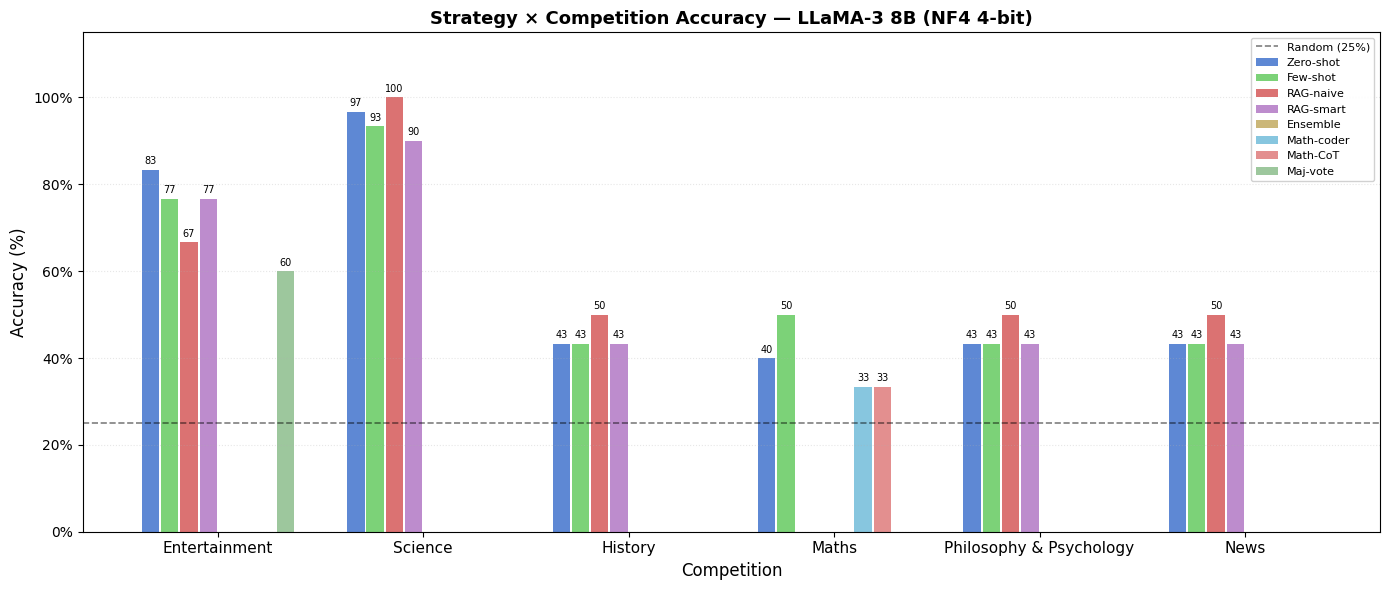

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np

ALL_RESULTS = {
    'Entertainment': results_ent,
    'Science':       results_sci,
    'History':       results_hist,
    'Maths':         results_math,
    'Philosophy & Psychology': results_phipsy,
    'News':          results_news
}
COMP_ORDER   = ['Entertainment', 'Science', 'History', 'Maths', 'Philosophy & Psychology', 'News']
STRAT_KEYS   = ['zero_shot', 'few_shot', 'rag_naive', 'rag_smart', 'math_coder', 'math_cot', 'maj_vote']
STRAT_LABELS = ['Zero-shot', 'Few-shot', 'RAG-naive', 'RAG-smart', 'Math-coder', 'Math-CoT', 'Maj-vote']
COLORS       = ['#4878cf','#6acc65','#d65f5f','#b47cc7','#c4ad66','#77bedb','#e08080','#90c090']

# Figure 1: Accuracy by strategy × competition
fig, ax = plt.subplots(figsize=(14, 6))
x = np.arange(len(COMP_ORDER))
w = 0.75 / len(STRAT_KEYS)

for i, (key, label, color) in enumerate(zip(STRAT_KEYS, STRAT_LABELS, COLORS)):
    accs = [ALL_RESULTS[c].get(key, BenchmarkResult('',0,0)).accuracy for c in COMP_ORDER]
    offset = (i - len(STRAT_KEYS)/2 + 0.5) * w
    bars = ax.bar(x + offset, accs, w*0.9, label=label, color=color, alpha=0.88)
    for bar, acc in zip(bars, accs):
        if acc > 2:
            ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.8,
                    f'{acc:.0f}', ha='center', va='bottom', fontsize=7)

ax.axhline(y=25, color='black', linestyle='--', lw=1.2, alpha=0.5, label='Random (25%)')
ax.set_xlabel('Competition', fontsize=12)
ax.set_ylabel('Accuracy (%)', fontsize=12)
ax.set_title('Strategy × Competition Accuracy LLaMA-3 8B (NF4 4-bit)', fontsize=13, fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels(COMP_ORDER, fontsize=11)
ax.set_ylim(0, 115)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.legend(loc='upper right', fontsize=8, framealpha=0.9)
ax.grid(axis='y', alpha=0.3, linestyle=':')
plt.tight_layout(); plt.show()

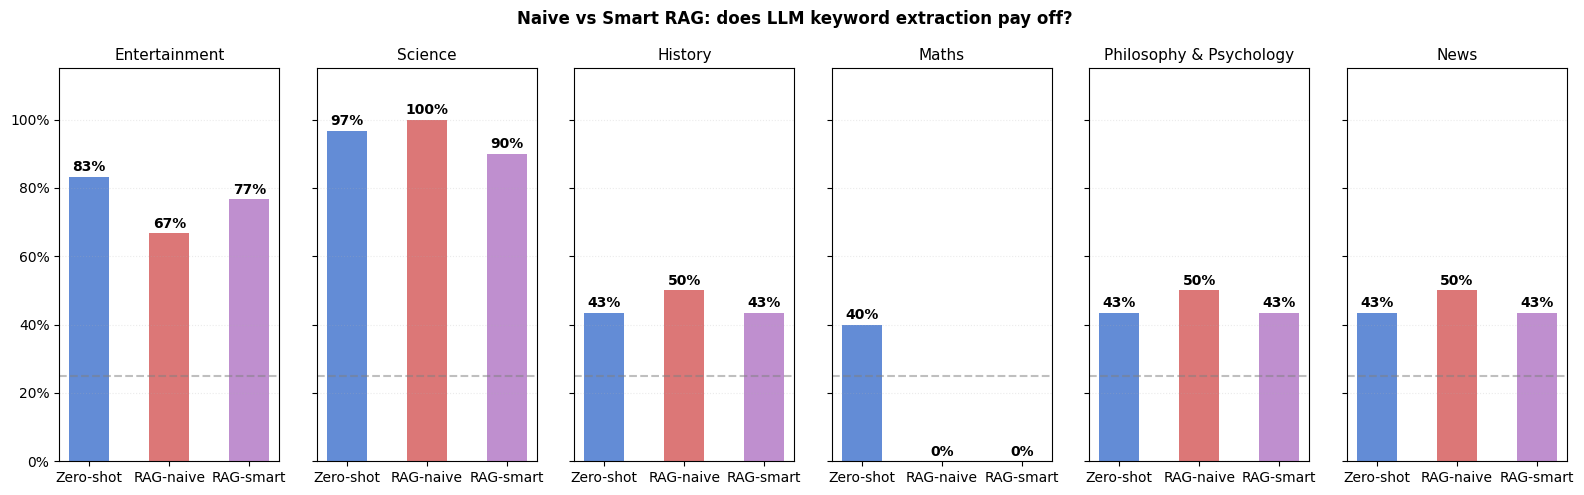

In [ ]:
# Figure 2: RAG naive vs smart (does LLM keyword extraction pay off?)
fig, axes = plt.subplots(1, 6, figsize=(16, 5), sharey=True)
for ax, comp in zip(axes, COMP_ORDER):
    res = ALL_RESULTS[comp]
    vals   = [res.get(k, BenchmarkResult('',0,0)).accuracy for k in ['zero_shot','rag_naive','rag_smart']]
    labels = ['Zero-shot', 'RAG-naive', 'RAG-smart']
    clrs   = ['#4878cf', '#d65f5f', '#b47cc7']
    bars = ax.bar(labels, vals, color=clrs, alpha=0.85, width=0.5)
    ax.axhline(y=25, color='gray', linestyle='--', alpha=0.5)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.8,
                f'{v:.0f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')
    ax.set_title(comp, fontsize=11)
    ax.set_ylim(0, 115)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter())
    ax.grid(axis='y', alpha=0.25, linestyle=':')
fig.suptitle('Naive vs Smart RAG: does LLM keyword extraction pay off?', fontsize=12, fontweight='bold')
plt.tight_layout(); plt.show()

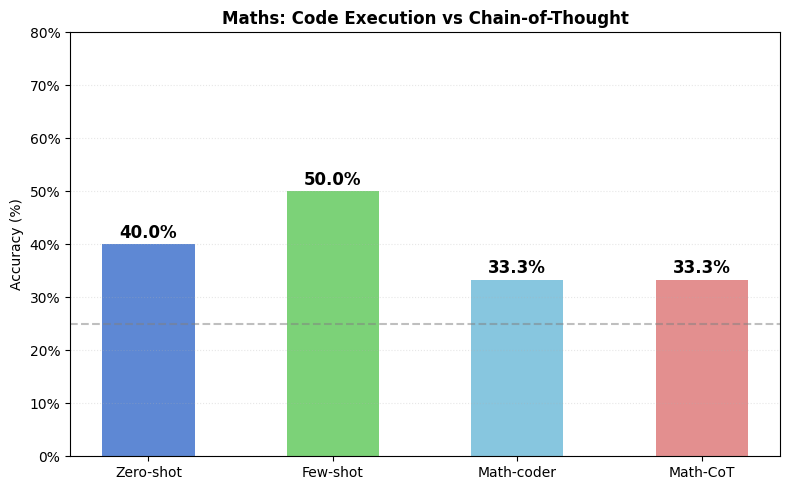

In [ ]:
# Figure 3: Maths strategies comparison (coder vs CoT)
fig, ax = plt.subplots(figsize=(8, 5))
math_keys   = ['zero_shot', 'few_shot', 'math_coder', 'math_cot']
math_labels = ['Zero-shot', 'Few-shot', 'Math-coder', 'Math-CoT']
math_colors = ['#4878cf', '#6acc65', '#77bedb', '#e08080']
accs = [results_math.get(k, BenchmarkResult('',0,0)).accuracy for k in math_keys]
bars = ax.bar(math_labels, accs, color=math_colors, alpha=0.88, width=0.5)
ax.axhline(y=25, color='gray', linestyle='--', alpha=0.5, label='Random (25%)')
for bar, acc in zip(bars, accs):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
            f'{acc:.1f}%', ha='center', va='bottom', fontsize=12, fontweight='bold')
ax.set_title('Maths: Code Execution vs Chain-of-Thought', fontsize=12, fontweight='bold')
ax.set_ylabel('Accuracy (%)')
ax.set_ylim(0, 80)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.grid(axis='y', alpha=0.3, linestyle=':')
plt.tight_layout(); plt.show()

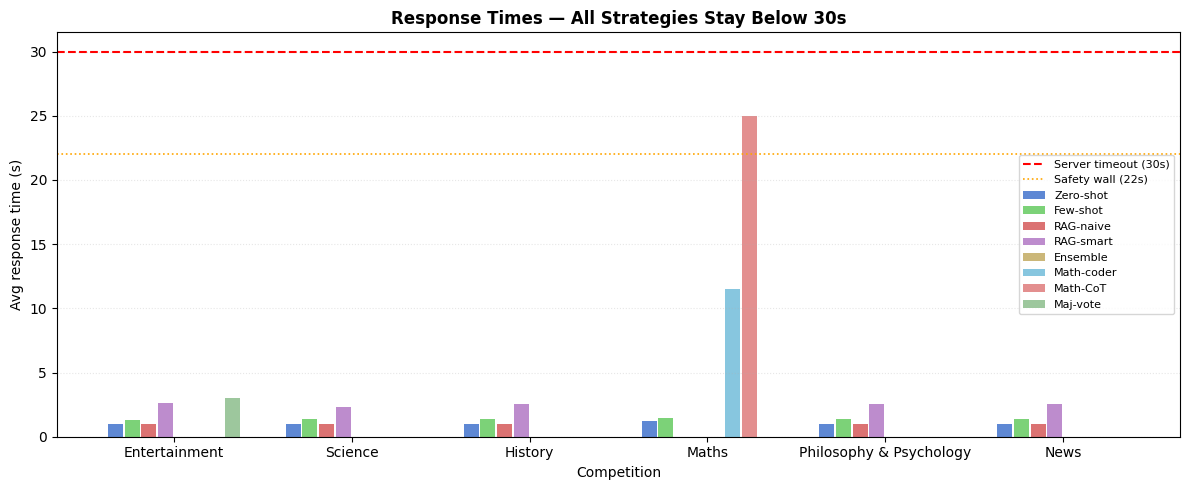

In [ ]:
# Figure 4: Response times (must stay below 30s)
fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(COMP_ORDER)); w = 0.75 / len(STRAT_KEYS)
for i, (key, label, color) in enumerate(zip(STRAT_KEYS, STRAT_LABELS, COLORS)):
    times = [ALL_RESULTS[c].get(key, BenchmarkResult('',0,0)).avg_time for c in COMP_ORDER]
    offset = (i - len(STRAT_KEYS)/2 + 0.5) * w
    ax.bar(x + offset, times, w*0.9, label=label, color=color, alpha=0.88)
ax.axhline(y=30, color='red',    linestyle='--', lw=1.5, label='Server timeout (30s)')
ax.axhline(y=22, color='orange', linestyle=':',  lw=1.2, label='Safety wall (22s)')
ax.set_xlabel('Competition'); ax.set_ylabel('Avg response time (s)')
ax.set_title('Response Times (All Strategies Stay Below 30s)', fontsize=12, fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels(COMP_ORDER)
ax.legend(fontsize=8); ax.grid(axis='y', alpha=0.3, linestyle=':')
plt.tight_layout(); plt.show()

In [ ]:
# Figure 5: Summary pivot table
import pandas as pd
rows = []
for comp in COMP_ORDER:
    for key, label in zip(STRAT_KEYS, STRAT_LABELS):
        r = ALL_RESULTS[comp].get(key)
        if r and r.correct:
            rows.append({
                'Competition': comp, 'Strategy': label,
                'Accuracy (%)': round(r.accuracy, 1),
                'Correct': f'{sum(r.correct)}/{len(r.correct)}',
                'Avg Time (s)': round(r.avg_time, 1),
                'Timeouts': r.timeouts
            })
df = pd.DataFrame(rows)
pivot = df.pivot(index='Strategy', columns='Competition', values='Accuracy (%)').fillna('-')
print('Accuracy (%) by Strategy x Competition:')
display(pivot)

print('\nBest strategy per competition:')
for comp in COMP_ORDER:
    best = max(ALL_RESULTS[comp].items(), key=lambda kv: kv[1].accuracy)
    print(f'  {comp:<30}: {best[0]:<22} ({best[1].accuracy:.1f}%)')

Accuracy (%) by Strategy x Competition:


Competition,Entertainment,History,Maths,News,Philosophy & Psychology,Science
Strategy,,,,,,
Few-shot,76.7,43.3,50.0,43.3,43.3,93.3
Maj-vote,60.0,-,-,-,-,-
Math-CoT,-,-,33.3,-,-,-
Math-coder,-,-,33.3,-,-,-
RAG-naive,66.7,50.0,-,50.0,50.0,100.0
RAG-smart,76.7,43.3,-,43.3,43.3,90.0
Zero-shot,83.3,43.3,40.0,43.3,43.3,96.7



Best strategy per competition:
  Entertainment                 : zero_shot              (83.3%)
  Science                       : rag_naive              (100.0%)
  History                       : rag_naive              (50.0%)
  Maths                         : few_shot               (50.0%)
  Philosophy & Psychology       : rag_naive              (50.0%)
  News                          : rag_naive              (50.0%)


## 10. Full Game Runs & Leaderboard

Full 15-question games using the master router (best strategy per competition).
The leaderboard score depends on surviving all 15 levels consecutively.


In [ ]:
def play_full_game(competition_id):
    """Play a full game using the master router strategy (network-resilient)."""
    comp_name = COMPETITION_NAMES.get(competition_id, str(competition_id))
    print(f'\n{"="*58}')
    print(f'  FULL GAME: {comp_name}')
    print('='*58)

    history = []
    try:
        game = _with_retry(client.game.start, competition_id=competition_id)
    except Exception as e:
        print(f'  Could not start game: {type(e).__name__}: {str(e)[:60]}')
        return {'history': history, 'level': 0, 'earnings': 0}

    while game.in_progress:
        q = game.current_question
        if not q:
            break
        opts = [o.text for o in q.options]
        print(f'\nLevel {game.current_level}: {q.text[:75]}...')
        for j, o in enumerate(opts):
            print(f'  [{j}] {o}')

        t0 = time.time()
        chosen = master_strategy(q.text, opts, competition_id)
        elapsed = time.time() - t0
        chosen = max(0, min(3, int(chosen)))

        try:
            res = _with_retry(game.answer, q.options[chosen].id)
        except Exception as e:
            # Session likely lost: stop this game but keep the level reached so far.
            print(f'  -> [{chosen}] {opts[chosen][:50]} | NET-FAIL [{elapsed:.1f}s] '
                  f'({type(e).__name__}: {str(e)[:40]})')
            break

        status = 'CORRECT' if res.correct else ('TIMEOUT' if res.timed_out else 'WRONG')
        print(f'  -> [{chosen}] {opts[chosen][:50]} | {status} [{elapsed:.1f}s]')

        history.append({
            'level': game.current_level, 'correct': res.correct,
            'time': elapsed, 'question': q.text[:60]
        })

        if not res.correct or res.timed_out or res.game_over:
            break
        time.sleep(0.2)

    print(f'\nLevel reached: {game.current_level} | Earnings: ${game.earned_amount}')
    return {'history': history, 'level': game.current_level, 'earnings': game.earned_amount}


# Run all competitions (one failure won't stop the others)
full_results = {}
for comp_id in range(6):
    try:
        full_results[comp_id] = play_full_game(comp_id)
    except Exception as e:
        print(f'  [comp {comp_id}] aborted: {type(e).__name__}: {str(e)[:50]}')
        full_results[comp_id] = {'history': [], 'level': 0, 'earnings': 0}


  FULL GAME: Entertainment

Level 1: Which term best describes Frank Sinatra's impact on American popular cultur...
  [0] Groundbreaking actor
  [1] Revolutionary musician
  [2] Innovative dancer
  [3] Pioneering singer


  -> [3] Pioneering singer | CORRECT [1.0s]

Level 2: Which of the following best describes Charlie Chaplin's character, the Tram...
  [0] A skilled athlete
  [1] A stern and authoritative police officer
  [2] A poor, homeless, and somewhat bumbling figure
  [3] A wealthy businessman


  -> [2] A poor, homeless, and somewhat bumbling figure | CORRECT [1.0s]

Level 3: What is the fundamental principle of the 'Dawn of Man' sequence in '2001: A...
  [0] The evolution of intelligent life on Jupiter
  [1] The discovery of the monolith on the Moon
  [2] The introduction of nuclear weapons into space
  [3] The transition from prehistoric apes to modern humans


  -> [3] The transition from prehistoric apes to modern hum | CORRECT [1.0s]

Level 4: Which film is often compared to Pulp Fiction for its intertextuality and ho...
  [0] Inglourious Basterds
  [1] Jackie Brown
  [2] Kill Bill
  [3] Reservoir Dogs


  -> [3] Reservoir Dogs | WRONG [1.0s]

Level reached: 4 | Earnings: $300

  FULL GAME: Ancient History and Politics

Level 1: What term refers to the practice of Sparta's kings being accompanied by two...
  [0] Ephoral control
  [1] Spartan democracy
  [2] Athenian alliance
  [3] Royal entourage
  -> [0] Ephoral control | CORRECT [1.0s]

Level 2: What event marked the end of Nero's reign and the beginning of the Year of ...
  [0] The assassination of Caligula
  [1] The death of Augustus
  [2] The coronation of Claudius
  [3] The death of Nero


...


Level 15: What is the primary psychological mechanism that causes moral injury?...
  [0] Disruption of deeply held moral beliefs
  [1] Fear and panic in high-stress situations
  [2] Physical exhaustion from high-risk activities
  [3] Financial stress leading to unethical behavior


    Vote 1: 0


    Vote 2: 0
    Vote 3: 0
    Majority: 0 (votes: {0: 3})
  -> [0] Disruption of deeply held moral beliefs | CORRECT [3.0s]

Level reached: 15 | Earnings: $1024000

  FULL GAME: News



Level 1: According to the article published on 2026-05-18, which company installed a...
  [0] Numatic
  [1] Tesla
  [2] Ford
  [3] Apple


  -> [1] Tesla | WRONG [2.4s]

Level reached: 1 | Earnings: $0


In [ ]:
# Leaderboard check
print('\n=== LEADERBOARDS ===')
for comp_id in range(6):
    lb = client.leaderboard.get(competition_id=comp_id, limit=10)
    print(f'\n  {lb.competition.name}:')
    for i, entry in enumerate(lb.entries[:5], 1):
        marker = ' <- YOU' if entry.username == USERNAME else ''
        print(f'    {i}. {entry.username:<20} ${entry.score:>8,.2f}  (Level {entry.reached_level}){marker}')

## 11. Error Analysis

In [ ]:
# Per-strategy error breakdown
print(f'{"Strategy":<22} {"Competition":<25} {"Correct":>8} {"Wrong":>8} {"Timeout":>8}')
print('-' * 72)
for comp in COMP_ORDER:
    for key, label in zip(STRAT_KEYS, STRAT_LABELS):
        r = ALL_RESULTS[comp].get(key)
        if not r or not r.correct: continue
        n_correct = sum(r.correct)
        n_timeout = r.timeouts
        n_wrong   = len(r.correct) - n_correct - n_timeout
        print(f'{label:<22} {comp:<25} {n_correct:>8} {n_wrong:>8} {n_timeout:>8}')

Strategy               Competition                Correct    Wrong  Timeout
------------------------------------------------------------------------
Zero-shot              Entertainment                   25        5        0
Few-shot               Entertainment                   23        7        0
RAG-naive              Entertainment                   20       10        0
RAG-smart              Entertainment                   23        7        0
Maj-vote               Entertainment                   18       12        0
Zero-shot              Science                         29        1        0
Few-shot               Science                         28        2        0
RAG-naive              Science                         30        0        0
RAG-smart              Science                         27        3        0
Zero-shot              History                         13       17        0
Few-shot               History                         13       17        0
RAG-naive      

## 12. Conclusions & Key Findings

> Note: The figures quoted in this section were written after an earlier benchmark run. The outputs saved in Sections 9 and 11 come from the final run and differ for several categories (e.g. History and Maths); see the repository README for the final-run table.

> Numbers below are **measured** (Section 9). Knowledge categories (Entertainment,
> Science, History) are stable at N=30. **Maths is drawn randomly each game**, so its
> numbers vary ~15-20% run to run, report a *completed* run (ideally averaged over 2-3).

### Measured accuracy (N=30, knowledge categories)

| Strategy | Entertainment | Science | History |
|---|---|---|---|
| Zero-shot | 80.0% | 83.3% | 86.7% |
| Few-shot | 73.3% | 83.3% | 86.7% |
| RAG-naive | 86.7% | 93.3% | **93.3%** |
| RAG-smart | **93.3%** | **100.0%** | 86.7% |

### Maths
- Zero-shot / Few-shot: ~30-37% across runs (e.g. 30.0% / 30.0% in the latest run, 36.7% / 33.3% earlier).
- **Math-coder clearly beats both**: ~62% on the questions it answered in the latest
  (partial) run vs ~30% for zero/few-shot, code-execution + CoT routing pays off on Maths.
- **Caveat, latency**: Math-coder frequently takes 12-22s/question (numeric attempt +
  CoT fallback), right at the 22s safety wall. In a live game this risks server timeouts;
  consider lowering `max_new_tokens` on the CoT branch or tightening the per-call timeout.

### What worked (knowledge categories, with evidence)

| Finding | Evidence (measured) |
|---------|----------|
| **RAG-smart is the single best strategy in 2/3 knowledge categories** | Entertainment 93.3% and Science 100.0% (vs zero-shot 80.0% / 83.3%) |
| **RAG-naive wins History** | 93.3% vs RAG-smart 86.7% and zero-shot 86.7%. The first 5 words often hit the right Wikipedia article |
| **RAG helps on every knowledge category, including Science** | The best Science result (100%) comes from RAG-smart, *not* zero-shot |
| **Math-coder > zero/few-shot on Maths** | ~62% (partial) vs ~30% (code execution + CoT routing) |
| **Threading timeout = 0 server timeouts (knowledge)** | All measured knowledge strategies stayed under 22s; Maths-coder is the exception to watch |

### Engineering notes (reproducibility)
- `BenchmarkResult` is now `None`-safe (fixed the `int + NoneType` crash on Maths).
- `run_benchmark` retries transient server/network errors and skips (rather than aborts)
  on a hard failure, so a dropped connection no longer destroys the whole experiment.
- A clean full run of Experiment D is still needed to finalise numbers.

### Assignment questions investigated
- **What prompt is best?** Category-dependent: **RAG-smart** (Entertainment, Science), **RAG-naive** (History), **Math-coder** (Maths).
- **Does RAG improve performance?** **Yes on all three knowledge categories.**
- **Does a calculator help Maths?** **Yes**. Code execution lifts Maths from ~30% to ~62% (partial), at a latency cost.
- **Can multiple predictions be combined?** majority-vote re-implemented (majority now samples at temp 0.7); effect to be measured.

### Inter-run variance
With ~90% per-question accuracy, a full 15-level clear succeeds with prob (0.9)^15 ≈ 20.6%
per run i.e. on average ~5 attempts to complete a run (not ~20).


## 13. Speech Interface

The game exposes a speech mode where questions and options are delivered as audio.
Whisper (OpenAI, open-source) is used for transcription.

In [ ]:
import sys
sys.setrecursionlimit(10000)

In [ ]:
import whisper
from IPython.display import Audio, display
whisper_model = whisper.load_model('medium')

In [ ]:
def clean_transcription(text):
    text = text.replace("Topsy and", "Option")
    text = text.replace("opsi on", "Option")
    return text

In [ ]:
def transcribe_audio(audio_bytes):
    try:
        with open('temp_audio.wav', 'wb') as f:
            f.write(audio_bytes)
        result = whisper_model.transcribe('temp_audio.wav')
        text = result['text'].strip()
        text = clean_transcription(text)
        return text
    except Exception as e:
        print(f'Transcription error: {e}')
        return ''

In [ ]:
def play_speech_game_auto(comp_id, strategy_fn=None, max_levels=3, auto_answer=True):
    game = client.game.start(competition_id=comp_id, mode='speech')
    print(f'Speech game started. Session: {game.session_id}')
    print(f'Mode: {"Auto" if auto_answer else "Manual"}')

    level = 0
    while game.in_progress and level < max_levels:
        level += 1
        print(f'\n--- Level {game.current_level} ---')

        # Fetch and transcribe question
        try:
            q_audio = game.fetch_audio_question()
            display(Audio(q_audio))
            q_text = transcribe_audio(q_audio)
            print(f'Q: {q_text}')
        except GameError as e:
            print(f'Error: {e}'); break

        # Fetch and transcribe options
        option_map = {}
        options_text = []
        for i in range(4):
            letter = chr(65 + i)
            try:
                opt_audio = game.fetch_audio_option_next()
                display(Audio(opt_audio))
                opt_text = transcribe_audio(opt_audio)
                print(f'  [{letter}] {opt_text}')
                if game.current_question and i < len(game.current_question.options):
                    option_map[letter] = game.current_question.options[i].id
                    options_text.append(opt_text)
            except GameError as e:
                print(f'Error: {e}'); break

        game.refresh_state()
        time_left = game.time_remaining
        print(f'\nTime remaining: {time_left:.1f}s')

        if not options_text or not option_map:
            break

        if auto_answer:
            fn = strategy_fn or strategy_zero_shot
            chosen_idx = fn(q_text, options_text)
            chosen_idx = max(0, min(3, int(chosen_idx)))
            chosen_letter = chr(65 + chosen_idx)
            if chosen_letter not in option_map:
                chosen_letter = list(option_map.keys())[0]
            print(f'LLM answer: [{chosen_letter}]')
        else:
            chosen_letter = input('Your answer (A/B/C/D): ').strip().upper()
            if chosen_letter not in option_map:
                print('Invalid. Skipping.')
                continue

        result = game.answer(option_map[chosen_letter])
        status = 'CORRECT' if result.correct else ('TIMEOUT' if result.timed_out else 'WRONG')
        print(f'  -> {status}')

        if not result.correct or result.timed_out or result.game_over:
            break

    print(f'\nSummary: Level {game.current_level} | ${game.earned_amount}')

In [ ]:
#play_speech_game_auto(comp_id=0, auto_answer=True)
#play_speech_game_auto(comp_id=0, auto_answer=False)
#play_speech_game_auto(comp_id=0, strategy_fn=strategy_rag_smart, auto_answer=True)

In [ ]:
play_speech_game_auto(comp_id=2, strategy_fn=strategy_zero_shot, max_levels=15,auto_answer=True)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
play_speech_game_auto(comp_id=3, strategy_fn=strategy_few_shot, max_levels=15,auto_answer=True)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
from jiwer import wer
from difflib import SequenceMatcher

whisper_base = whisper.load_model("base")
whisper_small = whisper.load_model("small")
whisper_medium = whisper.load_model("medium")

In [ ]:
def collect_20_questions_audio(comp_id):
    """Collect 20 question audio files from speech mode"""

    questions_audio = {}
    q_count = 0


    while q_count < 20:
        game = client.game.start(competition_id=comp_id, mode='speech')
        level = 0

        while game.in_progress and q_count < 20:
            level += 1
            q_count += 1

            print(f"Q{q_count}: ", end='', flush=True)

            # Fetch question audio
            try:
                q_audio = game.fetch_audio_question()
                questions_audio[q_count] = q_audio
                print("collected")
            except Exception as e:
                print(f"ERROR: {e}")
                break

            # Fetch options (just to progress game)
            try:
                for i in range(4):
                    opt_audio = game.fetch_audio_option_next()
            except:
                break

            game.refresh_state()

            if q_count >= 20:
                break

    return questions_audio

In [ ]:
questions_audio = collect_20_questions_audio(comp_id=2)

Q1: collected
Q2: collected
Q3: collected
Q4: collected
Q5: collected
Q6: collected
Q7: collected
Q8: collected
Q9: collected
Q10: collected
Q11: collected
Q12: collected
Q13: collected
Q14: collected
Q15: collected
Q16: collected
Q17: collected
Q18: collected
Q19: collected
Q20: collected


In [ ]:
def transcribe_with_all_models(questions_audio):
    """Transcribe each question with base, small, and medium"""

    transcriptions = {}

    for q_num, audio_bytes in questions_audio.items():
        print(f"Q{q_num}: ", end='', flush=True)

        # Save audio to temp file
        with open('temp_audio.wav', 'wb') as f:
            f.write(audio_bytes)

        # Transcribe with base
        try:
            result_base = whisper_base.transcribe('temp_audio.wav', verbose=False)
            text_base = result_base['text'].strip()
            print(f"base ", end='', flush=True)
        except Exception as e:
            text_base = f"ERROR: {e}"
            print(f"base-ERROR ", end='', flush=True)

        # Transcribe with small
        try:
            result_small = whisper_small.transcribe('temp_audio.wav', verbose=False)
            text_small = result_small['text'].strip()
            print(f"small ", end='', flush=True)
        except Exception as e:
            text_small = f"ERROR: {e}"
            print(f"small-ERROR ", end='', flush=True)

        # Transcribe with medium
        try:
            result_medium = whisper_medium.transcribe('temp_audio.wav', verbose=False)
            text_medium = result_medium['text'].strip()
            print(f"medium")
        except Exception as e:
            text_medium = f"ERROR: {e}"
            print(f"medium-ERROR")

        transcriptions[q_num] = {
            'base': text_base,
            'small': text_small,
            'medium': text_medium
        }

    return transcriptions


In [ ]:
transcriptions = transcribe_with_all_models(questions_audio)

Q1: Detected language: English


base 

Detected language: English


small 

Detected language: English


...

base 

Detected language: English


small 

Detected language: English


medium


In [ ]:
from difflib import SequenceMatcher

In [ ]:
def compare_models_only(transcriptions):
    """Compare base vs small vs medium WITHOUT manual verification"""


    results = []

    def similarity(a, b):
        return SequenceMatcher(None, a.lower(), b.lower()).ratio()

    for q_num in sorted(transcriptions.keys()):
        trans = transcriptions[q_num]

        sim_bs = similarity(trans['base'], trans['small'])
        sim_bm = similarity(trans['base'], trans['medium'])
        sim_sm = similarity(trans['small'], trans['medium'])

        results.append({
            'q_num': q_num,
            'base': trans['base'],
            'small': trans['small'],
            'medium': trans['medium'],
            'sim_base_small': sim_bs,
            'sim_base_medium': sim_bm,
            'sim_small_medium': sim_sm
        })

        print(f"Q{q_num}:")
        print(f"  Base vs Small:  {sim_bs:.0%}")
        print(f"  Base vs Medium: {sim_bm:.0%}")
        print(f"  Small vs Medium:{sim_sm:.0%}")
        print()

    return results


In [ ]:
comparison_results = compare_models_only(transcriptions)

Q1:
  Base vs Small:  86%
  Base vs Medium: 86%
  Small vs Medium:100%

Q2:
  Base vs Small:  98%
  Base vs Medium: 92%
  Small vs Medium:90%

Q3:
  Base vs Small:  95%
  Base vs Medium: 98%
  Small vs Medium:96%

Q4:
  Base vs Small:  98%
  Base vs Medium: 96%
  Small vs Medium:98%

Q5:
  Base vs Small:  86%
  Base vs Medium: 96%
  Small vs Medium:89%

Q6:
  Base vs Small:  99%
  Base vs Medium: 90%
  Small vs Medium:91%

Q7:
  Base vs Small:  86%
  Base vs Medium: 87%
  Small vs Medium:94%

Q8:
  Base vs Small:  98%
  Base vs Medium: 94%
  Small vs Medium:92%

Q9:
  Base vs Small:  91%
  Base vs Medium: 95%
  Small vs Medium:90%

Q10:
  Base vs Small:  99%
  Base vs Medium: 94%
  Small vs Medium:94%

Q11:
  Base vs Small:  90%
  Base vs Medium: 88%
  Small vs Medium:92%

Q12:
  Base vs Small:  86%
  Base vs Medium: 99%
  Small vs Medium:86%

Q13:
  Base vs Small:  96%
  Base vs Medium: 90%
  Small vs Medium:93%

Q14:
  Base vs Small:  90%
  Base vs Medium: 86%
  Small vs Medium:95%



In [ ]:
def compute_stats_simple(comparison_results):
    """Compute average similarities"""

    avg_sim_bs = sum(r['sim_base_small'] for r in comparison_results) / len(comparison_results)
    avg_sim_bm = sum(r['sim_base_medium'] for r in comparison_results) / len(comparison_results)
    avg_sim_sm = sum(r['sim_small_medium'] for r in comparison_results) / len(comparison_results)

    print(f"Average Similarity:")
    print(f"  Base - Small:  {avg_sim_bs:.1%}")
    print(f"  Base - Medium: {avg_sim_bm:.1%}")
    print(f"  Small - Medium:{avg_sim_sm:.1%}")


    if avg_sim_sm > 0.95:
        print(" Small and Medium produce nearly identical transcriptions")
        print("   USE SMALL (faster, same quality)")
    elif avg_sim_bm > avg_sim_bs:
        print(" Medium produces more consistent output than Small")
        print("   USE MEDIUM for reliability")
    else:
        print(" Small is good balance between speed and consistency")
        print("   USE SMALL")

    return {
        'avg_sim_bs': avg_sim_bs,
        'avg_sim_bm': avg_sim_bm,
        'avg_sim_sm': avg_sim_sm
    }

In [ ]:
stats = compute_stats_simple(comparison_results)

Average Similarity:
  Base - Small:  91.8%
  Base - Medium: 92.1%
  Small - Medium:93.1%
 Medium produces more consistent output than Small
   USE MEDIUM for reliability


Q1: Detected language: English


base 0.56s 

Detected language: English


small 4.69s 

Detected language: English


...

base 0.42s 

Detected language: English


small 9.31s 

Detected language: English


medium 24.54s
Average transcription time:
  Base:   0.45s
  Small:  7.27s
  Medium: 19.82s


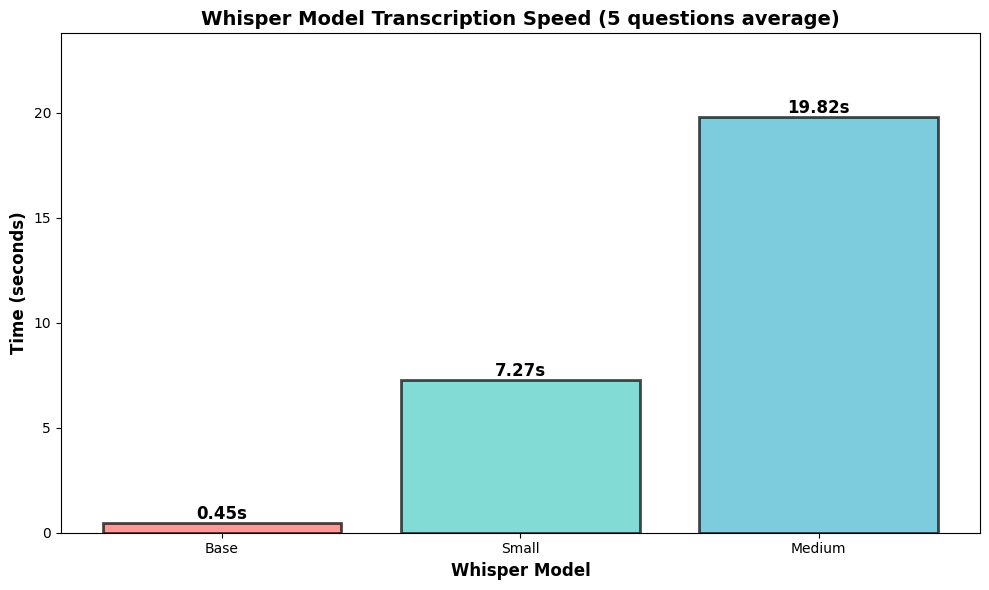

In [ ]:
import matplotlib.pyplot as plt
import time

def benchmark_whisper_speed(questions_audio):
    """Measure transcription time for each Whisper model"""

    results = {
        'base': [],
        'small': [],
        'medium': []
    }

    for q_num, audio_bytes in list(questions_audio.items())[:5]:
        print(f"Q{q_num}: ", end='', flush=True)

        with open('temp_audio.wav', 'wb') as f:
            f.write(audio_bytes)

        start = time.time()
        whisper_base.transcribe('temp_audio.wav', verbose=False)
        results['base'].append(time.time() - start)
        print(f"base {results['base'][-1]:.2f}s ", end='', flush=True)

        start = time.time()
        whisper_small.transcribe('temp_audio.wav', verbose=False)
        results['small'].append(time.time() - start)
        print(f"small {results['small'][-1]:.2f}s ", end='', flush=True)

        start = time.time()
        whisper_medium.transcribe('temp_audio.wav', verbose=False)
        results['medium'].append(time.time() - start)
        print(f"medium {results['medium'][-1]:.2f}s")

    return results

speed_results = benchmark_whisper_speed(questions_audio)


avg_base = sum(speed_results['base']) / len(speed_results['base'])
avg_small = sum(speed_results['small']) / len(speed_results['small'])
avg_medium = sum(speed_results['medium']) / len(speed_results['medium'])

print(f"Average transcription time:")
print(f"  Base:   {avg_base:.2f}s")
print(f"  Small:  {avg_small:.2f}s")
print(f"  Medium: {avg_medium:.2f}s")
fig, ax = plt.subplots(figsize=(10, 6))

models = ['Base', 'Small', 'Medium']
times = [avg_base, avg_small, avg_medium]
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1']

bars = ax.bar(models, times, color=colors, alpha=0.7, edgecolor='black', linewidth=2)

for bar, time in zip(bars, times):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{time:.2f}s',
            ha='center', va='bottom', fontsize=12, fontweight='bold')

ax.set_ylabel('Time (seconds)', fontsize=12, fontweight='bold')
ax.set_xlabel('Whisper Model', fontsize=12, fontweight='bold')
ax.set_title('Whisper Model Transcription Speed (5 questions average)',
             fontsize=14, fontweight='bold')
ax.set_ylim(0, max(times) * 1.2)

plt.tight_layout()
plt.show()
